# ARAI exploratory data analysis

This notebook explores the generated development worlds before any model exists. It follows
`final-spec/components/05-data-exploration.md` (specification v1.3). It was extended after an independent review
(`records/2026-10-02-eda-critic-review.md`) with an audit of mechanical artefacts, a preview of the gate's benign
segments, prevalence by opportunity count and intervals on the style signals.

**Scope.** Fixture worlds (seeds 2001-2003, 1,000 customers), training worlds (2101-2110, 10,000 customers) and
stress worlds (2501-2507, one mechanism changed in each). Validation and test worlds are **not generated yet**:
the specification allows them only after difficulty calibration and the gate dry run, and they may never guide
a fix.

**Private truth is used throughout.** These are offline diagnostics. Nothing computed here may become an
operational feature, and none of these numbers is a claim about real customers: the worlds are simulations
built from the specification's assumptions.

**Reading the tables.** Every count says what it counts: units, lines, orders or customers. A ratio with a zero
denominator is shown as empty, never as zero.

Run `uv run arai generate --seed 2001 2002 2003 2101 2102 2103 2104 2105 2106 2107 2108 2109 2110 2501 2502 2503
2504 2505 2506 2507` first; this notebook reads the written worlds from `data/`.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from arai import diagnostics, eda
from arai.generator import load_world
from arai.paths import ARTIFACT_ROOT, REPO_ROOT
from arai.settings import STRESS_OVERRIDES, load_settings
from arai.validation import validate_world

pd.set_option("display.max_columns", 40, "display.width", 220, "display.precision", 3, "display.max_rows", 60)
settings = load_settings()
experiment = settings.experiment
FIXTURES = [f"W{s}" for s in experiment["fixture_seeds"]]
TRAINING = [f"W{s}" for s in experiment["train_seeds"]]
STRESS = [f"W{s}" for s in experiment["stress_seeds"]]
REFERENCE = TRAINING[0]
REPORT_DIR = REPO_ROOT / "reports" / "eda" / "2026-10-02"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SURFACE, INK, SECONDARY, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, QUIET = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": SECONDARY, "ytick.labelcolor": SECONDARY,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 1. Load and validate every development world

Each world is validated again from its written files, then summarised once. The summaries are small tables;
the worlds themselves are released after use.

In [2]:
collected, loaded = {}, []
started = time.time()
for world_id in FIXTURES + TRAINING + STRESS:
    report = validate_world(ARTIFACT_ROOT / "worlds" / world_id / "operational")
    world = load_world(world_id)
    seed = world.manifest["generator"]["seed"]
    collected[world_id] = eda.collect(world, load_settings(seed))
    loaded.append({"world": world_id, "purpose": world.purpose, "validated": report.accepted,
                   "customers": len(world.tables["customer_master"]), "orders": len(world.tables["sales_order"]),
                   "sale_lines": len(world.tables["sales_order_line"]), "return_lines": len(world.tables["return_order_line"]),
                   "stress_change": json.dumps(STRESS_OVERRIDES.get(seed, {})) if seed in STRESS_OVERRIDES else ""})
    if world_id == REFERENCE:
        reference = world
    del world
loaded = pd.DataFrame(loaded)
print(f"{len(loaded)} worlds summarised in {time.time() - started:.0f}s; all validated: {bool(loaded['validated'].all())}")
assert loaded["validated"].all()
display(loaded)

20 worlds summarised in 386s; all validated: True


,world,purpose,validated,customers,orders,sale_lines,return_lines,stress_change
0,W2001,fixture,True,1000,8551,13539,2742,
1,W2002,fixture,True,1000,8837,14100,2743,
2,W2003,fixture,True,1000,7380,11722,2318,
3,W2101,train,True,10000,81660,130416,27112,
4,W2102,train,True,10000,80648,129137,26498,
5,W2103,train,True,10000,80223,128515,25780,
6,W2104,train,True,10000,81866,131078,26762,
7,W2105,train,True,10000,80970,129444,26077,
8,W2106,train,True,10000,80923,129845,26978,
9,W2107,train,True,10000,82928,132591,27251,


## 2. Structure and coverage

Counts, keys and empty cells for the reference training world, then the feasibility checks for every world:
no order before signup or before the SKU's launch, and nothing after the cutoff.

In [3]:
display(collected[REFERENCE]["structure"])
coverage = pd.DataFrame({w: c["coverage"] for w, c in collected.items()}).T
display(coverage)
assert (coverage[["orders_before_signup", "lines_before_sku_launch", "requests_after_cutoff"]] == 0).all().all()

,table,rows,columns,duplicate_keys,columns_with_nulls
0,customer_master,10000,5,0,none
1,sku_master,300,13,0,none
2,reason_code,16,7,0,none
3,sales_order,81660,11,0,none
4,sales_order_line,130416,11,0,"shipped_date (4204), delivered_date (6140)"
5,return_order,24747,7,0,none
6,return_order_line,27112,14,0,"return_received_flag (1354), reason_text (2711..."


,first_order,last_order,first_signup,customers_signed_up_before_history,orders_before_signup,lines_before_sku_launch,requests_after_cutoff,currencies,customers_without_orders
W2001,2025-09-10,2026-09-09,2023-09-10,581,0,0,0,[INR],300
W2002,2025-09-10,2026-09-09,2023-09-11,613,0,0,0,[INR],265
W2003,2025-09-10,2026-09-09,2023-09-11,604,0,0,0,[INR],301
W2101,2025-09-10,2026-09-09,2023-09-10,5885,0,0,0,[INR],2954
W2102,2025-09-10,2026-09-09,2023-09-10,5855,0,0,0,[INR],3017
W2103,2025-09-10,2026-09-09,2023-09-10,5869,0,0,0,[INR],3062
W2104,2025-09-10,2026-09-09,2023-09-10,5928,0,0,0,[INR],3045
W2105,2025-09-10,2026-09-09,2023-09-10,5957,0,0,0,[INR],3055
W2106,2025-09-10,2026-09-09,2023-09-10,5861,0,0,0,[INR],3035
W2107,2025-09-10,2026-09-09,2023-09-10,5845,0,0,0,[INR],2920


Empty cells appear only where the contract allows them: shipping and delivery dates of lines not yet shipped or
delivered, the received flag of no-item claims, and the two evidence-only text columns the generator leaves empty.

## 3. Sales distributions (reference training world)

In [4]:
dist = eda.distributions(reference)
display(pd.DataFrame({"lines per order": dist["lines_per_order"], "quantity per line": dist["quantity_per_line"]}).T.fillna(""))
display(pd.concat([dist["orders_per_customer"], dist["order_total_inr"]], axis=1).T)
display(pd.DataFrame({"sale line state": dist["line_status"]}).T)
display(pd.DataFrame({"return line state": dist["return_line_status"]}).T)
print("discounted lines:", dist["discounted_line_share"], "| mature share of delivered lines:", dist["mature_share_of_delivered_lines"],
      "| orders with two sizes of one style:", dist["bracketed_order_share"])
print("customers without any order:", collected[REFERENCE]["coverage"]["customers_without_orders"], "of", len(reference.tables["customer_master"]))

,1,2,3,4,5,6
lines per order,0.549,0.332,0.098,0.019,0.003,0.0
quantity per line,0.920,0.070,0.010,,,


,0.10,0.25,0.50,0.75,0.90,0.99
orders per customer,0.0,0.0,3.0,11.0,22.0,74.01
order total (INR),1104.0,1599.0,2858.0,4698.0,6948.0,12545.00


line_status,delivered,cancelled,shipped,lost_in_transit,awaiting_dispatch
sale line state,0.953,0.03,0.012,0.003,0.003


line_status,refunded,rejected,withdrawn,pending
return line state,0.926,0.033,0.026,0.015


discounted lines: 0.4492 | mature share of delivered lines: 0.9036 | orders with two sizes of one style: 0.0293
customers without any order: 2954 of 10000


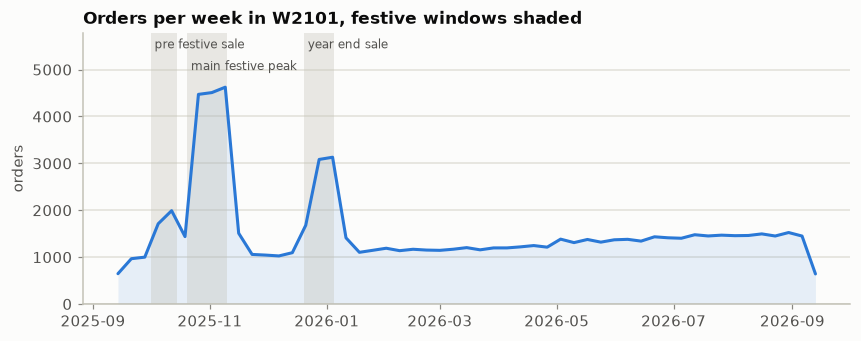

In [5]:
weekly = reference.tables["sales_order"].set_index("order_date").resample("W").size()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(weekly.index, weekly.values, color=BLUE)
ax.fill_between(weekly.index, weekly.values, color=BLUE, alpha=0.10, linewidth=0)
top = weekly.max() * 1.25
for position, window in enumerate(settings.festive_windows):
    start = pd.Timestamp(f"2025-{window['start']}")
    end = pd.Timestamp(f"{2026 if window.get('crosses_year') else 2025}-{window['end']}")
    ax.axvspan(start, end, color=QUIET, alpha=0.35, linewidth=0)
    ax.text(start, top * (0.98 - 0.08 * (position % 2)), " " + window["name"].replace("_", " ").lower(), ha="left", va="top",
            fontsize=8, color=SECONDARY)
ax.set_ylim(0, top)
ax.set_title(f"Orders per week in {REFERENCE}, festive windows shaded")
ax.set_ylabel("orders")
ax.grid(axis="x", visible=False)
plt.show()

## 4. Reasons and timing

Reasons are what the customer states, not a ruling. The timing table shows where in the return window each kind
of request arrives (0 = delivery day, 1 = last day of the window), pooled over the ten training worlds.

group,fit,discretionary,transaction claim,quality complaint,carrier damage
share of return lines,0.449,0.366,0.101,0.062,0.022


,count,mean,50%,90%
kind,,,,
deceptive claim,7888.0,0.168,0.133,0.333
honest,243191.0,0.274,0.250,0.500
temporary use,3622.0,0.716,0.733,0.900


,count,mean,50%,90%
group,,,,
carrier damage,6262.0,0.306,0.267,0.533
discretionary,92862.0,0.306,0.267,0.533
fit,112598.0,0.305,0.267,0.533
quality complaint,15717.0,0.307,0.267,0.533
transaction claim,19777.0,0.174,0.133,0.356


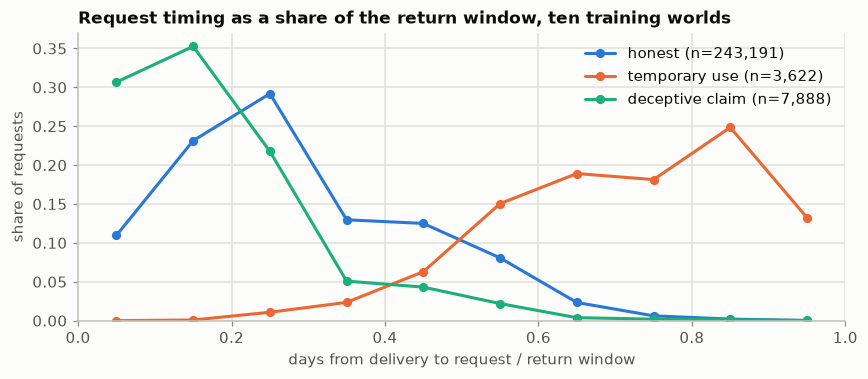

honest late requests (after the window): 0.0163
honest requests at or after 75% of the window: 0.0207


In [6]:
reasons = eda.reasons_and_timing(reference)
display(pd.DataFrame({"share of return lines": reasons["reason_group_share"]}).T)
timing = pd.concat([collected[w]["timing"] for w in TRAINING], ignore_index=True)
timing["kind"] = timing["intent"].map({"honest": "honest", "temporary_use_return": "temporary use"}).fillna("deceptive claim")
in_window = timing[timing["window_ratio"] <= 1]
display(in_window.groupby("kind")["window_ratio"].describe(percentiles=[0.5, 0.9])[["count", "mean", "50%", "90%"]])
display(timing[timing["intent"] == "honest"].groupby("group")["window_ratio"].describe(percentiles=[0.5, 0.9])[["count", "mean", "50%", "90%"]])

bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(9, 3.4))
for kind, colour in (("honest", BLUE), ("temporary use", ORANGE), ("deceptive claim", AQUA)):
    values = in_window.loc[in_window["kind"] == kind, "window_ratio"]
    share = np.histogram(values, bins=bins)[0] / len(values)
    ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, marker="o", markersize=5, label=f"{kind} (n={len(values):,})")
ax.set_title("Request timing as a share of the return window, ten training worlds")
ax.set_xlabel("days from delivery to request / return window")
ax.set_ylabel("share of requests")
ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
plt.show()
print("honest late requests (after the window):", round(float((timing.loc[timing['intent'] == 'honest', 'window_ratio'] > 1).mean()), 4))
print("honest requests at or after 75% of the window:", round(float((timing.loc[timing['intent'] == 'honest', 'window_ratio'] >= 0.75).mean()), 4))

## 4b. Artefact audit: can anything mechanical tell abusive requests from honest ones?

A model should find abuse through behaviour, not through a quirk of how the generator writes rows. This audit
compares honest, solo-abuse and ring-abuse requests on everything that is *not* meant to differ: claim timing,
the shape of the order under the claim, the order of lines inside a return header, and request outcomes. The
last three rows are specified differences (abusive requests are never withdrawn, late or multi-unit).

Shares are the mean of the ten training worlds; the two count rows are totals.

In [7]:
audits = pd.concat({w: collected[w]["audit"] for w in TRAINING})
audit = audits.groupby(level=1, sort=False).mean()
totals = ["claim lines", "requests: lines out of time order in their header"]
audit.loc[totals] = audits.groupby(level=1, sort=False).sum().loc[totals]
display(audit.round(3))
slow = audits.xs("claims: share more than 10 days after delivery", level=1)
print("claims more than 10 days after delivery, range across worlds:")
display(slow.agg(["min", "max"]).round(3))
assert audit.loc["requests: lines out of time order in their header"].sum() == 0
assert audits.xs("claims: maximum days", level=1).max().max() <= 30

order_kinds = pd.concat({w: collected[w]["orders"]["by_kind"] for w in TRAINING})
by_kind = order_kinds.groupby(level=1).mean()
by_kind["orders"] = order_kinds.groupby(level=1)["orders"].sum()
display(by_kind.round(3))
same_day = max(collected[w]["orders"]["same_day_repeat_order_share"] for w in FIXTURES + TRAINING + STRESS)
print("largest share of same-day repeat orders in any world:", same_day)
assert same_day == 0

monthly = sum(collected[w]["orders"]["monthly"] for w in TRAINING).fillna(0).astype(int)
display(monthly.T)
linked_claimants = pd.DataFrame({w: collected[w]["linked"] for w in TRAINING}).T
display(linked_claimants)
print(f"customers with a linked claim, ten worlds: {int(linked_claimants['linked_claimants'].sum())}, of whom honest "
      f"{int(linked_claimants['honest'].sum())} ({linked_claimants['honest'].sum() / linked_claimants['linked_claimants'].sum():.1%})")

kind,honest,solo abuse,ring abuse
claim lines,19777.000,6151.000,1737.000
claims: median days after delivery,5.000,5.000,4.950
claims: 95th percentile days,14.285,13.900,13.690
claims: maximum days,29.200,25.100,20.900
claims: share more than 10 days after delivery,0.137,0.127,0.142
claims: share on single-line orders,0.338,0.497,0.572
claims: share on single-unit orders,0.290,0.449,0.528
claims: share on lines delivered in the last 90 days,0.228,0.218,0.320
claims: share on lines not yet mature,0.084,0.085,0.132
requests: lines out of time order in their header,0.000,0.000,0.000


claims more than 10 days after delivery, range across worlds:


kind,honest,solo abuse,ring abuse
min,0.127,0.106,0.115
max,0.153,0.149,0.172


,orders,single_line_share,mean_lines,mean_units,mean_order_total
kind,,,,,
base order,795348,0.548,1.600,1.744,3541.142
campaign order,1877,0.578,1.560,1.701,4184.613
household co-order,16181,0.547,1.602,1.746,3548.405


largest share of same-day repeat orders in any world: 0.0


order_date,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
kind,,,,,,,,,,,,,
base order,28497,122827,93367,81216,62889,45446,51843,52074,56617,57230,61359,63244,18739
campaign order,57,143,112,127,130,121,132,172,173,191,207,235,77
household co-order,497,2098,1782,1498,1343,911,1087,1143,1219,1308,1431,1424,440


,linked_claimants,honest,honest_household_members,honest_ring_members,abusers
W2101,60,4,4,0,56
W2102,44,2,2,0,42
W2103,60,7,7,0,53
W2104,60,12,12,0,48
W2105,39,4,4,0,35
W2106,62,5,5,0,57
W2107,65,6,6,0,59
W2108,55,11,11,0,44
W2109,71,11,11,0,60
W2110,50,6,6,0,44


customers with a linked claim, ten worlds: 566, of whom honest 68 (12.0%)


What remains different, and why it is left in:

- **Order shape under a claim.** Abusers claim once per order whatever its size, while genuine failures scale
  with the number of units, so honest claims sit on larger orders more often. This is behaviour as specified, not
  an identifier, and none of the 18 features reads the size of the order under a claim.
- **Recency.** Ring claims fall somewhat more often in the last 90 days than honest ones, because rings only act
  once their members have signed up and the customer base grows through the year.
- **Withdrawn, late and multi-unit requests** are honest only, by specification.

## 5. Generation targets against what the worlds realised

Targets are probabilities, not quotas. The table shows the mean, lowest and highest realised value across the ten
training worlds.

In [8]:
targets = pd.concat([collected[w]["targets"] for w in TRAINING], ignore_index=True)
across = targets.groupby("measure", sort=False).agg(target=("target", "mean"), realised_mean=("realised", "mean"),
                                                   realised_min=("realised", "min"), realised_max=("realised", "max"))
across["mean_relative_deviation"] = (across["realised_mean"] / across["target"] - 1).round(3)
display(across)
targets.to_csv(REPORT_DIR / "targets_vs_realised.csv", index=False)

,target,realised_mean,realised_min,realised_max,mean_relative_deviation
measure,,,,,
"claim propensity, share of accounts",0.040,0.040,0.038,0.043,0.000
"temporary-use propensity, share of accounts",0.030,0.031,0.029,0.032,0.017
"both propensities, share of accounts",0.005,0.006,0.005,0.007,0.110
mean action rate of propensity accounts,0.200,0.198,0.192,0.206,-0.012
genuine fulfilment failure per delivered unit,0.015,0.015,0.014,0.016,0.012
carrier damage per delivered unit,0.005,0.005,0.005,0.005,0.003
cancelled share of lines,0.030,0.030,0.029,0.030,-0.007
"household members, share of accounts",0.120,0.120,0.120,0.120,-0.000
"heavy-return overlay, share of accounts",0.060,0.055,0.053,0.058,-0.091


## 6. Eligibility and the abuse it excludes

Only customers with at least three mature sale lines are ranked. Abusers with thinner history are excluded from
the ranking and must be reported, not hidden.

In [9]:
keys = ["customers", "eligible_customers", "excluded_customers", "excluded_without_any_order", "abusers_all",
        "abusers_eligible", "abusers_excluded", "prevalence_all", "prevalence_eligible", "prevalence_excluded",
        "excluded_abuse_share_of_all_abusers", "review_budget_k_at_5pct"]
eligibility = pd.DataFrame({w: {k: collected[w]["eligibility"][k] for k in keys} for w in FIXTURES + TRAINING}).T
display(eligibility)
pooled = eligibility.loc[TRAINING, keys[:7]].sum()
print(f"training worlds pooled: {int(pooled['eligible_customers']):,} of {int(pooled['customers']):,} customers eligible "
      f"({pooled['eligible_customers'] / pooled['customers']:.1%}); {int(pooled['abusers_eligible']):,} of {int(pooled['abusers_all']):,} abusers eligible; "
      f"{pooled['abusers_excluded'] / pooled['abusers_all']:.1%} of abusers excluded; prevalence among eligible "
      f"{pooled['abusers_eligible'] / pooled['eligible_customers']:.2%}")
display(sum(collected[w]["eligibility"]["completed_actions_by_type"] for w in TRAINING))
eligibility.to_csv(REPORT_DIR / "eligibility.csv")

,customers,eligible_customers,excluded_customers,excluded_without_any_order,abusers_all,abusers_eligible,abusers_excluded,prevalence_all,prevalence_eligible,prevalence_excluded,excluded_abuse_share_of_all_abusers,review_budget_k_at_5pct
W2001,1000.0,521.0,479.0,300.0,32.0,28.0,4.0,0.032,0.054,0.008,0.125,27.0
W2002,1000.0,573.0,427.0,265.0,30.0,30.0,0.0,0.030,0.052,0.000,0.000,29.0
W2003,1000.0,518.0,482.0,301.0,29.0,20.0,9.0,0.029,0.039,0.019,0.310,26.0
W2101,10000.0,5317.0,4683.0,2954.0,321.0,286.0,35.0,0.032,0.054,0.007,0.109,266.0
W2102,10000.0,5349.0,4651.0,3017.0,339.0,296.0,43.0,0.034,0.055,0.009,0.127,268.0
W2103,10000.0,5240.0,4760.0,3062.0,328.0,279.0,49.0,0.033,0.053,0.010,0.149,262.0
W2104,10000.0,5309.0,4691.0,3045.0,329.0,298.0,31.0,0.033,0.056,0.007,0.094,266.0
W2105,10000.0,5259.0,4741.0,3055.0,328.0,307.0,21.0,0.033,0.058,0.004,0.064,263.0
W2106,10000.0,5256.0,4744.0,3035.0,330.0,289.0,41.0,0.033,0.055,0.009,0.124,263.0
W2107,10000.0,5353.0,4647.0,2920.0,342.0,291.0,51.0,0.034,0.054,0.011,0.149,268.0


training worlds pooled: 53,024 of 100,000 customers eligible (53.0%); 2,876 of 3,258 abusers eligible; 11.7% of abusers excluded; prevalence among eligible 5.42%


,completed_actions,on_eligible_customers
action_type,,
deceptive_contents_claim,4024,3860
deceptive_nonreceipt_claim,3864,3672
temporary_use_return,3622,3523


## 7. Opportunities, completions and blocks

Each row is an abusive opportunity the generator drew (actions, not customers). An opportunity that could not
complete keeps its reason and is never retried.

In [10]:
opportunities = sum(collected[w]["opportunities"] for w in TRAINING).fillna(0).astype(int)
display(opportunities)
sources = pd.concat([collected[w]["hot_list"] for w in TRAINING])[["attempts", "completed", "campaign_orders", "reused_purchases"]].sum()
print("ring campaign attempts by claim source, pooled:", sources.astype(int).to_dict())

outcome                                   after_cutoff    all  cancelled  claim_after_cutoff  completed  lost_in_transit  no_unreserved_unit  request_after_cutoff  undelivered_by_cutoff  unit_conflict
scope         action_type                                                                                                                                                                               
ring campaign deceptive_contents_claim               0    966          0                   0        878                0                   0                     0                      0              0
              deceptive_nonreceipt_claim             0    943          0                   0        859                0                   0                     0                      0              0
solo          deceptive_contents_claim               0   3675          0                   0       3146                0                 452                    62                      0             15
              deceptive_nonreceipt_claim             0   3516          0                   0       3005                0                 435                    55                      0             21
              temporary_use_return                   0   4327          0                   0       3622                0                 331                   330                      0             44
all                                                  0  13427          0                   0      11510                0                1218                   447                      0             80

ring campaign attempts by claim source, pooled: {'attempts': 1909, 'completed': 1737, 'campaign_orders': 1882, 'reused_purchases': 27}


## 8. Prevalence by persona and by order count, and two label-free shortcuts

Abuse propensity is assigned independently of return behaviour, with a higher chance for two personas. But an
account with more orders has more chances to act, so completed abuse is more common among heavy buyers even when
propensity is equal. The specification expects this and asks for it to be measured, not assumed away.

The shortcut table scores held-out training worlds (2106-2110) with rules that never look at return behaviour:
persona alone (prevalence learned on 2101-2105) and order count alone. An AUC of 0.5 would mean no information.

,customers,eligible,abusers,abusers_eligible,prevalence,prevalence_eligible
persona,,,,,,
Dormant,11011,0,0,0,0.000,NaN
High_Intensity,2029,1801,197,194,0.097,0.108
Loyalist,15878,15647,896,892,0.056,0.057
New_Growth,15211,2725,302,155,0.020,0.057
Occasional,37902,19175,1085,900,0.029,0.047
Seasonal,17969,13676,778,735,0.043,0.054


,customers,eligible,abusers,abusers_eligible,prevalence,prevalence_eligible
order_bucket,,,,,,
0,30047,0,0,0,0.000,NaN
1-2,19352,4467,390,111,0.020,0.025
3-5,13702,11724,632,534,0.046,0.046
6-10,11844,11779,592,587,0.050,0.050
11-20,12944,12943,797,797,0.062,0.062
21+,12111,12111,847,847,0.070,0.070


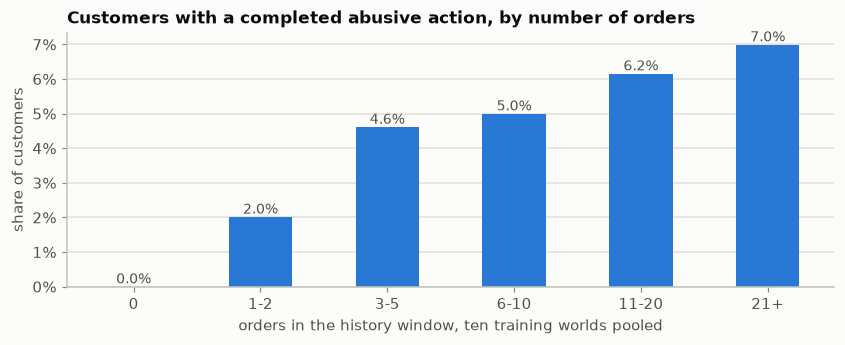

accounts with an abuse propensity, by number of relevant (delivered, base-layer) orders:


,propensity_accounts,opportunities_drawn,acted,share_that_acted
bucket,,,,
0,1357,227,130,0.096
1-2,1533,798,456,0.297
3-5,1010,1107,543,0.538
6-10,801,1565,561,0.700
11-20,950,3282,791,0.833
21+,848,6448,777,0.916


,population,customers,abusers,persona_only_auc,order_count_only_auc,raw_return_rate_auc,claim_count_auc
0,all customers,50000,1613,0.652,0.733,0.854,0.841
1,eligible customers,26550,1410,0.534,0.570,0.786,0.813


In [11]:
persona = pd.concat([collected[w]["persona"] for w in TRAINING], ignore_index=True)
persona["order_bucket"] = pd.cut(persona["orders"], eda.ORDER_BUCKETS, right=False, labels=eda.ORDER_BUCKET_LABELS)
def prevalence(key):
    grouped = persona.groupby(key, observed=True)
    out = grouped.agg(customers=("customer_id", "size"), eligible=("eligible", "sum"), abusers=("y_abuse", "sum"))
    out["abusers_eligible"] = persona[persona["eligible"]].groupby(key, observed=True)["y_abuse"].sum().reindex(out.index, fill_value=0)
    out["prevalence"] = out["abusers"] / out["customers"]
    out["prevalence_eligible"] = out["abusers_eligible"] / out["eligible"].replace(0, np.nan)
    return out
by_persona, by_orders = prevalence("persona"), prevalence("order_bucket")
display(by_persona); display(by_orders)

fig, ax = plt.subplots(figsize=(9, 3))
bars = ax.bar(by_orders.index.astype(str), by_orders["prevalence"], width=0.5, color=BLUE)
for bar, value in zip(bars, by_orders["prevalence"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.1%}", ha="center", va="bottom", fontsize=9, color=SECONDARY)
ax.set_title("Customers with a completed abusive action, by number of orders")
ax.set_xlabel("orders in the history window, ten training worlds pooled")
ax.set_ylabel("share of customers")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
plt.show()

opportunity = sum(collected[w]["opportunity"] for w in TRAINING)
opportunity["share_that_acted"] = opportunity["acted"] / opportunity["propensity_accounts"]
print("accounts with an abuse propensity, by number of relevant (delivered, base-layer) orders:")
display(opportunity)

train_half = persona[persona["world_id"].isin(TRAINING[:5])]
held_out = persona[persona["world_id"].isin(TRAINING[5:])]
shortcuts = eda.held_out_auc(train_half, held_out)
display(shortcuts)
shortcuts.to_csv(REPORT_DIR / "shortcut_auc.csv", index=False)

## 9. Overlapping groups and evaluation segment sizes

Action types overlap (one customer can make both kinds of claim), and so do the three benign segments the gate
compares on. Overlapping groups are shown as a matrix and never added up as if they were disjoint. The gate
needs at least 200 pooled members per segment on the validation worlds; the training worlds show whether five
worlds will be enough.

In [12]:
display(collected[REFERENCE]["overlap"]["action_type_overlap_customers"])
display(collected[REFERENCE]["overlap"]["benign_segment_overlap_customers"])
segments = pd.DataFrame({w: collected[w]["segments"] for w in FIXTURES + TRAINING + STRESS}).T
segments["eligible_honest"] = [collected[w]["overlap"]["eligible_honest_customers"] for w in segments.index]
display(segments.loc[FIXTURES + TRAINING])
five_world = segments.loc[TRAINING[:5], ["legit_heavy_returner", "defective_product_buyer", "benign_household"]].sum()
print("pooled over five training worlds (the size of the validation set):", five_world.to_dict(),
      "| smallest segment clears 200:", bool(five_world.min() >= 200))
segments.to_csv(REPORT_DIR / "segments.csv")

# what the two reference rules would do to the gate's benign segments (the candidates must not do worse than the first)
preview = pd.concat([collected[w]["gate_preview"] for w in TRAINING]).groupby("rule").sum(numeric_only=True)
for name in ("legit_heavy_returner", "defective_product_buyer", "benign_household"):
    preview[name + "_fpr"] = preview[name + "_selected"] / preview[name + "_size"]
preview["precision"] = preview["true_positives"] / preview["selected"]
display(preview[["selected", "precision", "legit_heavy_returner_fpr", "defective_product_buyer_fpr", "benign_household_fpr"]].round(4))
preview.to_csv(REPORT_DIR / "rule_gate_preview.csv")

,deceptive_nonreceipt_claim,deceptive_contents_claim,temporary_use_return
deceptive_nonreceipt_claim,182,120,10
deceptive_contents_claim,120,159,8
temporary_use_return,10,8,112


,legit_heavy_returner,defective_product_buyer,benign_household
legit_heavy_returner,429,135,49
defective_product_buyer,135,1053,130
benign_household,49,130,623


,legit_heavy_returner,defective_product_buyer,benign_household,eligible_honest
W2001,46,107,72,493
W2002,47,119,66,543
W2003,46,110,65,498
W2101,429,1053,623,5031
W2102,437,1034,636,5053
W2103,458,1044,660,4961
W2104,489,1072,649,5011
W2105,495,1004,654,4952
W2106,423,1055,627,4967
W2107,514,1164,629,5062


pooled over five training worlds (the size of the validation set): {'legit_heavy_returner': 2308, 'defective_product_buyer': 5207, 'benign_household': 3222} | smallest segment clears 200: True


,selected,precision,legit_heavy_returner_fpr,defective_product_buyer_fpr,benign_household_fpr
rule,,,,,
rank by number of claims,2655,0.402,0.052,0.076,0.030
rank by raw return rate,2655,0.213,0.446,0.060,0.042


## 10. Genuine and deceptive use of the same reason codes, and where evidence is missing

Every code a deceptive action uses must also be used honestly in the same world, or the code itself would give
the answer away. The second table shows, for eligible customers, how often a piece of evidence simply does not
exist. Where it is missing for most honest customers and present for most abusers, a model can learn from the
gap alone, which is worth knowing before features are built.

In [13]:
codes = sum(collected[w]["codes"].drop(columns=["deceptive_share", "code_has_honest_use"]) for w in TRAINING).fillna(0).astype(int)
codes["deceptive_share"] = (codes["deceptive_or_temporary"] / (codes["deceptive_or_temporary"] + codes["honest"])).round(3)
display(codes.sort_values("deceptive_share", ascending=False))
every_world = all(collected[w]["codes"].loc[collected[w]["codes"]["deceptive_or_temporary"] > 0, "code_has_honest_use"].all()
                  for w in FIXTURES + TRAINING + STRESS)
print("every deceptively used code also has honest use, in every world:", every_world)
assert every_world
support = sum(collected[w]["support"] for w in TRAINING) / len(TRAINING)
display(support.round(3))
codes.to_csv(REPORT_DIR / "code_overlap.csv")

intent,deceptive_contents_claim,deceptive_nonreceipt_claim,honest,temporary_use_return,deceptive_or_temporary,deceptive_share
reason_code,,,,,,
item_not_received,0,3864,6407,0,3864,0.376
empty_package,1350,0,2671,0,1350,0.336
wrong_item_sent,1332,0,5305,0,1332,0.201
missing_parts,1342,0,5394,0,1342,0.199
poor_quality,0,0,5239,271,271,0.049
not_as_described,0,0,5294,269,269,0.048
changed_my_mind,0,0,15526,284,284,0.018
found_better_price,0,0,15503,266,266,0.017
ordered_by_mistake,0,0,15390,270,270,0.017


every deceptively used code also has honest use, in every world: True


,undefined for abuser,undefined for honest
any return request,0.000,0.199
any transaction claim,0.248,0.803
any request on a mature line,0.008,0.214
any supported neighbour,0.598,0.898


## 11. Action rates and address clustering

Two mechanisms set the difficulty. Abusers differ in how often they act, so some act only once. Genuine delivery
failures cluster at a few addresses, so some honest customers have several genuine claims.

In [14]:
rates = collected[REFERENCE]["rates"]
print(f"{REFERENCE}: {rates['propensity_accounts']} accounts with a propensity, {rates['propensity_accounts_that_acted']} acted at least once; "
      f"one-off abusers {rates['one_off_abuser_share']:.0%}; action rate below 5% for {rates['rate_below_5pct_share']:.0%} of propensities")
display(pd.DataFrame({"action rate": rates["rate_quantiles"]}).T)
display(pd.DataFrame({"completed actions per abuser": rates["completed_actions_per_abuser"]}).T)
acted = pd.DataFrame({w: {"propensity_accounts": collected[w]["rates"]["propensity_accounts"],
                          "acted": collected[w]["rates"]["propensity_accounts_that_acted"],
                          "one_off_share": collected[w]["rates"]["one_off_abuser_share"]} for w in TRAINING}).T
print(f"pooled: {acted['acted'].sum() / acted['propensity_accounts'].sum():.1%} of propensity accounts act at least once; "
      f"one-off share ranges {acted['one_off_share'].min():.0%}-{acted['one_off_share'].max():.0%}")

address = collected[REFERENCE]["addresses"]
display(address["by_address_multiplier"])
repeat = pd.DataFrame({w: {"honest customers with 2+ genuine claims": collected[w]["addresses"]["honest_customers_with_2plus_genuine_claims"],
                           "honest customers with 3+ genuine claims": collected[w]["addresses"]["honest_customers_with_3plus_genuine_claims"],
                           "abusers (all)": collected[w]["eligibility"]["abusers_all"]} for w in TRAINING}).T
display(repeat)

W2101: 677 accounts with a propensity, 321 acted at least once; one-off abusers 33%; action rate below 5% for 15% of propensities


,0.05,0.25,0.50,0.75,0.95
action rate,0.019,0.086,0.162,0.277,0.481


,0.25,0.50,0.75,0.95
completed actions per abuser,1.0,2.0,4.0,9.0


pooled: 50.1% of propensity accounts act at least once; one-off share ranges 30%-41%


,delivered_units,genuine_claim_units,claim_rate,share_of_genuine_claims
bucket,,,,
<0.25x,50387,188,0.004,0.095
0.25-1x,42133,401,0.009,0.202
1-2x,22651,445,0.020,0.224
2-4x,14216,496,0.035,0.250
>=4x,5978,454,0.076,0.229


,honest customers with 2+ genuine claims,honest customers with 3+ genuine claims,abusers (all)
W2101,349,172,321
W2102,390,174,339
W2103,405,211,328
W2104,408,204,329
W2105,403,186,328
W2106,401,186,330
W2107,375,183,342
W2108,376,179,315
W2109,388,186,316
W2110,414,183,310


## 12. Relationships: assigned sharing against what the identifiers show

Group membership is private. The model will only see which accounts share identifiers, and an edge needs two
shared identifier types. Households and rings both create edges, so a link alone is not evidence of abuse.

In [15]:
relationships = collected[REFERENCE]["relationships"]
display(relationships["usage"]); display(relationships["fanout"]); display(relationships["linked_by_group"])
print("connected components of the supported graph:", relationships["components"])
print("share of linked accounts that are ring members:", round(relationships["linked_accounts_that_are_ring_members_share"], 3))
linked = pd.concat([collected[w]["relationships"]["linked_by_group"].assign(world=w) for w in TRAINING])
pooled_links = linked.groupby("group")[["accounts", "with_supported_neighbour"]].sum()
pooled_links["share"] = pooled_links["with_supported_neighbour"] / pooled_links["accounts"]
display(pooled_links)
fanout = pd.DataFrame({w: collected[w]["relationships"]["fanout"]["dropped_above_cap"] for w in FIXTURES + TRAINING}).T
print("identifier values dropped for exceeding the fan-out cap of 25, per world:"); display(fanout)

members_with_orders  mean_sampled_probability  mean_realised_usage  never_used
group_type      identifier_type                                                                                
coordination    address                          103                     0.841                0.829           5
                device                           184                     0.846                0.812           8
                payment                          179                     0.859                0.872           4
household       address                          891                     0.749                0.716          61
                device                           613                     0.750                0.743          31
                payment                          296                     0.759                0.749          12
shared_location address                          115                     0.748                0.754           5

,values,shared_by_2plus,dropped_above_cap,largest
address,7101,308,2,37
device,8364,243,0,6
payment,8788,140,0,6


,group,accounts,with_supported_neighbour,share
0,household members,1200,591,0.492
1,coordination-group members,271,180,0.664
2,shared-location members,153,9,0.059
3,ungrouped accounts,8420,0,0.000


connected components of the supported graph: {'count': 250, 'largest': 9, 'size_distribution': {2: 100, 3: 89, 4: 33, 5: 20, 6: 6, 7: 1, 9: 1}}
share of linked accounts that are ring members: 0.24


,accounts,with_supported_neighbour,share
group,,,
coordination-group members,2598,1582,0.609
household members,11997,6266,0.522
shared-location members,1280,90,0.070
ungrouped accounts,84612,0,0.000


identifier values dropped for exceeding the fan-out cap of 25, per world:


,address,device,payment
W2001,0,0,0
W2002,0,0,0
W2003,0,0,0
W2101,2,0,0
W2102,1,0,0
W2103,1,0,0
W2104,0,0,0
W2105,3,0,0
W2106,2,0,0
W2107,2,0,0


## 13. Style evidence against private style truth

Each training world has three defect-prone styles and a hot list of four ring-target styles. A style counts as
*targeted* only when one ring has at least three accounts completing claims on it. The table evaluates the two
style signals over all 370 style-worlds at several thresholds. The specification's defaults were a
linked-claim share of 0.10 and a damage share of 0.30, to be confirmed on development worlds. This evidence
led to adopting 0.075 for the linked-claim share (decision AM-25): now that honest linked claims exist, 0.05
lets two untargeted styles through, while 0.075 lets none through and still finds 33 of 38. The `state` column
below uses 0.075. The intervals show how wide the uncertainty is with 38 targeted styles.

In [16]:
display(collected[REFERENCE]["hot_list"])
styles = pd.concat([collected[w]["styles"] for w in TRAINING], ignore_index=True)
display(pd.crosstab([styles["defect_state"], styles["targeting_level"]], styles["state"], margins=True))
detectors = eda.detector_table(styles)
display(detectors)
display(styles.groupby("targeting_level")[["claim_lines", "linked_claimers", "linked_claim_share"]].describe(percentiles=[0.5])
        .loc[:, (slice(None), ["count", "min", "50%", "max"])])
display(styles.groupby("defect_state")["damage_share"].describe(percentiles=[0.5])[["count", "min", "50%", "max"]])
styles.to_csv(REPORT_DIR / "style_evidence.csv", index=False)
detectors.to_csv(REPORT_DIR / "detector_thresholds.csv", index=False)

,style_id,rings_planned,rings_completed,targeting_level,attempts,completed,completing_accounts,campaign_orders,reused_purchases
7,BA-TSH-02,7,7,targeted,26,26,14,26,0
15,BB-SHT-03,23,20,targeted,66,62,45,64,2
30,BD-JNS-02,19,15,targeted,34,31,26,34,0
35,BE-JKT-01,25,19,targeted,71,65,43,69,2


state                         mixed_or_uncertain  no_elevated_signal  quality  targeting  All
defect_state targeting_level                                                                 
defect_prone none                              0                   0       26          0   26
             targeted                          4                   0        0          0    4
ordinary     none                              0                 304        0          0  304
             sub_threshold                     0                   2        0          0    2
             targeted                          0                   5        0         29   34
All                                            4                 311       26         29  370

,signal,truth_positive_styles,fired,true_positives,fired_on_sub_threshold,precision,recall,recall_95,precision_95
0,"targeting, linked share >= 0.05",38,36,34,0,0.944,0.895,"(0.7586916879980553, 0.9582981020673341)","(0.8185502589238878, 0.9846303362329332)"
1,"targeting, linked share >= 0.075",38,33,33,0,1.000,0.868,"(0.7267282994850112, 0.9424621712426856)","(0.8957265699643882, 1.0)"
2,"targeting, linked share >= 0.1",38,30,30,0,1.000,0.789,"(0.6365391162355784, 0.8892533964790407)","(0.8864829086095221, 1.0)"
3,"targeting, three linked claimants only",38,38,36,0,0.947,0.947,"(0.8271423311893115, 0.9854460975514631)","(0.8271423311893115, 0.9854460975514631)"
4,"quality, damage share >= 0.3",30,30,30,0,1.000,1.000,"(0.8864829086095221, 1.0)","(0.8864829086095221, 1.0)"
5,"quality, damage share >= 0.5",30,0,0,0,NaN,0.000,"(-1.3877787807814457e-17, 0.113517091390478)","(None, None)"


claim_lines                     linked_claimers                  linked_claim_share                     
                      count   min    50%    max           count  min   50%   max              count    min    50%    max
targeting_level                                                                                                         
none                  330.0  40.0   70.0   97.0           330.0  0.0   0.0   4.0              330.0  0.000  0.000  0.055
sub_threshold           2.0  73.0   74.0   75.0             2.0  0.0   1.0   2.0                2.0  0.000  0.014  0.027
targeted               38.0  79.0  114.5  166.0            38.0  2.0  13.5  37.0               38.0  0.025  0.154  0.288

,count,min,50%,max
defect_state,,,,
defect_prone,30.0,0.379,0.405,0.448
ordinary,340.0,0.007,0.023,0.051


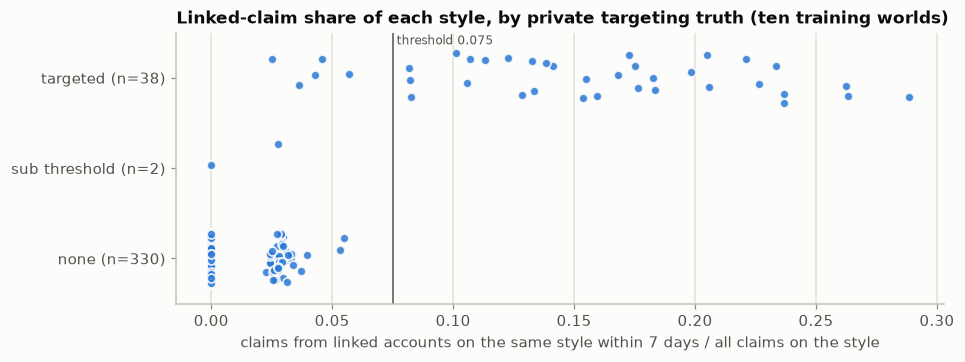

In [17]:
levels = ["none", "sub_threshold", "targeted"]
jitter = np.random.default_rng(0).uniform(-0.28, 0.28, len(styles))
fig, ax = plt.subplots(figsize=(9, 3.2))
position = styles["targeting_level"].map({level: i for i, level in enumerate(levels)}).to_numpy()
ax.scatter(styles["linked_claim_share"].fillna(0), position + jitter, s=34, color=BLUE, edgecolor=SURFACE, linewidth=1.2, alpha=0.85)
for threshold in (0.075,):
    ax.axvline(threshold, color=SECONDARY, linewidth=1)
    ax.text(threshold, 2.48, f" threshold {threshold}", fontsize=8, color=SECONDARY, va="top")
counts = styles["targeting_level"].value_counts()
ax.set_yticks(range(3), [f"{level.replace('_', ' ')} (n={counts.get(level, 0)})" for level in levels])
ax.set_ylim(-0.5, 2.5)
ax.set_title("Linked-claim share of each style, by private targeting truth (ten training worlds)")
ax.set_xlabel("claims from linked accounts on the same style within 7 days / all claims on the style")
ax.grid(axis="y", visible=False)
plt.show()

## 14. Two simple rules as a first reference

The specification's baseline ranks eligible customers by raw return rate and reviews the top 5%. A second rule
ranks by number of claims. Both are scored per world and pooled (pooled precision = all true positives over all
selections). The calibration target for the return-rate rule is 20-30%.

rule,rank by number of claims,rank by raw return rate
world,,
W2101,0.406,0.233
W2102,0.410,0.213
W2103,0.347,0.218
W2104,0.395,0.207
W2105,0.418,0.171
W2106,0.395,0.221
W2107,0.422,0.235
W2108,0.422,0.241
W2109,0.381,0.192


,k,true_positives,eligible_positives,precision,recall,ceiling_precision
rule,,,,,,
rank by number of claims,2655,1066,2876,0.402,0.371,1.0
rank by raw return rate,2655,566,2876,0.213,0.197,1.0


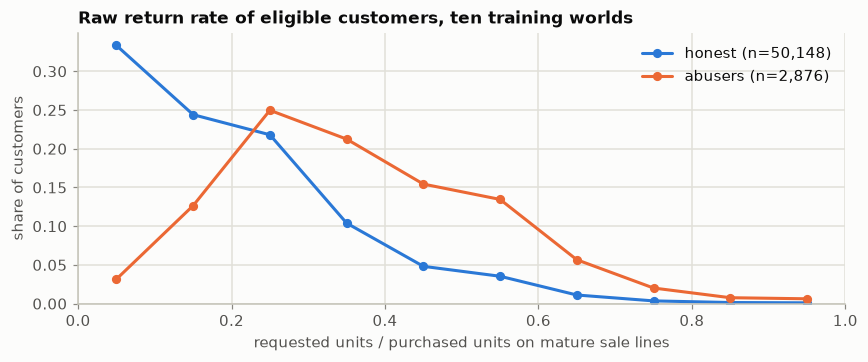

In [18]:
rows = []
for w in FIXTURES + TRAINING:
    for rule, result in collected[w]["rules"].items():
        rows.append({"world": w, "rule": rule, **result})
rules = pd.DataFrame(rows)
display(rules[rules["world"].isin(TRAINING)].pivot(index="world", columns="rule", values="precision").round(3))
pooled_rules = rules[rules["world"].isin(TRAINING)].groupby("rule")[["k", "true_positives", "eligible_positives"]].sum()
pooled_rules["precision"] = pooled_rules["true_positives"] / pooled_rules["k"]
pooled_rules["recall"] = pooled_rules["true_positives"] / pooled_rules["eligible_positives"]
pooled_rules["ceiling_precision"] = np.minimum(1.0, pooled_rules["eligible_positives"] / pooled_rules["k"])
display(pooled_rules)
rules.to_csv(REPORT_DIR / "rule_baselines.csv", index=False)

eligible = persona[persona["eligible"]]
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(9, 3.2))
for label, mask, colour in (("honest", eligible["y_abuse"] == 0, BLUE), ("abusers", eligible["y_abuse"] == 1, ORANGE)):
    values = eligible.loc[mask, "raw_return_rate"]
    share = np.histogram(values, bins=bins)[0] / len(values)
    ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, marker="o", markersize=5, label=f"{label} (n={len(values):,})")
ax.set_title("Raw return rate of eligible customers, ten training worlds")
ax.set_xlabel("requested units / purchased units on mature sale lines")
ax.set_ylabel("share of customers")
ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
plt.show()

## 15. Stress worlds: one mechanism at a time

Each stress world changes one setting. The table puts the measures that setting should move beside the mean of
the ten training worlds. World 2507 sets every actionable persona multiplier to 1; in that world abuse
propensity must not depend on persona, which the last check tests.

In [19]:
stress = pd.DataFrame({w: collected[w]["stress"] for w in TRAINING + STRESS}).T.astype(float)
table = stress.loc[STRESS].copy()
table.loc["training mean"] = stress.loc[TRAINING].mean()
table.insert(0, "change", [json.dumps(STRESS_OVERRIDES[int(w[1:])]) for w in STRESS] + [""])
display(table)
table.to_csv(REPORT_DIR / "stress.csv")

independence = eda.allocation_independence(load_world("W2507"))
display(independence["propensity_share_by_persona"])
print(f"W2507 (all multipliers 1): chi-square {independence['chi2']} on {independence['dof']} df, p = {independence['p_value']}")
normal = eda.allocation_independence(reference)
display(normal["propensity_share_by_persona"])
print(f"{REFERENCE} (multipliers 1 / 1.5 / 2): chi-square {normal['chi2']} on {normal['dof']} df, p = {normal['p_value']}")

,change,propensity_share,mean_action_rate,completed_actions,honest_requested_units_per_delivered_unit,defect_prone_styles,defective_product_buyers,household_member_share,benign_household_segment,prevalence_eligible,return_rate_rule_precision_at_5pct
W2501,"{""ordinary_propensity_scale"": 1.2}",0.067,0.197,1077.0,0.219,3.0,1127.0,0.12,646.0,0.058,0.211
W2502,"{""ordinary_propensity_scale"": 0.8}",0.064,0.198,1139.0,0.154,3.0,929.0,0.12,648.0,0.051,0.261
W2503,"{""defect_incidence_scale"": 2.0}",0.063,0.201,1087.0,0.188,6.0,1556.0,0.12,622.0,0.057,0.229
W2504,"{""household_share_scale"": 2.0}",0.064,0.206,1166.0,0.182,3.0,1081.0,0.24,1305.0,0.053,0.178
W2505,"{""action_rate_scale"": 0.5}",0.064,0.094,668.0,0.185,3.0,1097.0,0.12,697.0,0.046,0.105
W2506,"{""action_rate_scale"": 2.0}",0.062,0.400,1822.0,0.188,3.0,1097.0,0.12,675.0,0.057,0.423
W2507,"{""actionable_multipliers_all_one"": true}",0.064,0.199,1254.0,0.187,3.0,1067.0,0.12,672.0,0.057,0.189
training mean,,0.065,0.198,1151.0,0.187,3.0,1057.2,0.12,646.8,0.054,0.213


,accounts,propensity_share
persona,,
High_Intensity,207,0.082
Loyalist,1573,0.074
New_Growth,1363,0.076
Occasional,3495,0.077
Seasonal,1811,0.075


W2507 (all multipliers 1): chi-square 0.24 on 4 df, p = 0.9933


,accounts,propensity_share
persona,,
High_Intensity,213,0.178
Loyalist,1558,0.071
New_Growth,1390,0.113
Occasional,3562,0.071
Seasonal,1801,0.066


W2101 (multipliers 1 / 1.5 / 2): chi-square 59.54 on 4 df, p = 0.0


## 16. Saved summary

In [20]:
summary = {
    "date": "2026-10-02", "specification": "1.2", "worlds": {"fixture": FIXTURES, "training": TRAINING, "stress": STRESS},
    "validation_and_test_worlds_generated": False,
    "training_pooled": {
        "customers": int(pooled["customers"]), "eligible_customers": int(pooled["eligible_customers"]),
        "abusers_all": int(pooled["abusers_all"]), "abusers_eligible": int(pooled["abusers_eligible"]),
        "prevalence_eligible": float(pooled["abusers_eligible"] / pooled["eligible_customers"]),
        "excluded_abuse_share": float(pooled["abusers_excluded"] / pooled["abusers_all"]),
        "rule_precision_at_5pct": pooled_rules["precision"].round(4).to_dict(),
        "segment_sizes_five_worlds": {k: int(v) for k, v in five_world.items()},
    },
    "shortcut_auc_held_out": shortcuts.to_dict(orient="records"),
    "style_signals": detectors.to_dict(orient="records"),
    "artefact_audit": {"out_of_order_header_lines": int(audit.loc["requests: lines out of time order in their header"].sum()),
                       "largest_same_day_repeat_order_share": same_day,
                       "linked_claimants": int(linked_claimants["linked_claimants"].sum()), "honest_linked_claimants": int(linked_claimants["honest"].sum())},
    "w2507_allocation_independence": {"chi2": independence["chi2"], "dof": independence["dof"], "p_value": independence["p_value"]},
}
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float) + "\n", encoding="utf-8")
print(json.dumps(summary["training_pooled"], indent=1, default=float))
print("reports written to", REPORT_DIR.relative_to(REPO_ROOT))

{
 "customers": 100000,
 "eligible_customers": 53024,
 "abusers_all": 3258,
 "abusers_eligible": 2876,
 "prevalence_eligible": 0.05423958961979481,
 "excluded_abuse_share": 0.1172498465316145,
 "rule_precision_at_5pct": {
  "rank by number of claims": 0.4015,
  "rank by raw return rate": 0.2132
 },
 "segment_sizes_five_worlds": {
  "legit_heavy_returner": 2308,
  "defective_product_buyer": 5207,
  "benign_household": 3222
 }
}
reports written to reports\eda\2026-10-02


## Limits

- These are simulated worlds. Every rate here follows from a design assumption in the specification, and no
  number is evidence about real customers or real abuse.
- All worlds come from one generator and one configuration, so agreement between worlds, and cross-validation
  grouped by world, show that results are stable, not that they would hold on real data.
- Thresholds confirmed here were confirmed on the same ten worlds they are reported on; the intervals in section 13
  show how little 40 targeted styles can establish.
- Features and models do not exist yet. The two rules in section 14 are references, not the evaluation, and the
  difficulty targets for the best model cannot be checked until the candidates are trained.
- The findings and the decisions they led to are recorded in `records/2026-10-02-eda.md`.